# Shape Optimization of a 3D Truss Bridge

This notebook optimizes the geometry of a 3D steel-truss-like bridge: the positions of the
interior nodes are moved so that the bridge becomes **as stiff as possible** under a
distributed deck load, **without using more material** than the initial design.

* **Structural model:** linear elastic 3D truss, solved with the finite element method (`src/truss.py`)
* **Sensitivities:** obtained automatically with PyTorch autograd, no hand-derived gradients
* **Optimizer:** Method of Moving Asymptotes (MMA, Svanberg) with a dual solve (`src/optimization.py`)

In [1]:
import sys

import matplotlib.pyplot as plt
import torch

sys.path.insert(0, "src")
from optimization import optimize_mma
from truss import Truss

torch.set_default_dtype(torch.float64)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

## 1. Geometry, loads and supports

The bridge is 5 long, 0.5 wide and 0.5 high and consists of two parallel planar trusses
connected by bracing. Node numbering: `j * 20 + i * 2 + k`, where `i` runs along the span
(10 stations), `j` across the width (2 planes) and `k` over the height (bottom / top chord).

* **Loads:** a downward force on every bottom-chord node (deck load)
* **Supports:** the four bottom corner nodes are pinned

In [2]:
A, B, C = 10, 2, 2  # nodes along x, y, z

x_ = torch.linspace(0.0, 5.0, A)
y_ = torch.linspace(0.0, 0.5, B)
z_ = torch.linspace(0.0, 0.5, C)
X, Y, Z = torch.meshgrid(x_, y_, z_, indexing="xy")
nodes = torch.stack([X.ravel(), Y.ravel(), Z.ravel()], dim=1)

connections = []
for k in range(C):
    for j in range(B):
        for i in range(A - 1):
            connections.append([i + j * A + k * A * B, i + 1 + j * A + k * A * B])
for j in range(B):
    for i in range(A):
        for k in range(C - 1):
            connections.append([i + j * A + k * A * B, i + j * A + (k + 1) * A * B])

connections += [
    # top chords
    [1, 3], [3, 5], [5, 7], [7, 9], [9, 11], [11, 13], [13, 15], [15, 17], [17, 19],
    [21, 23], [23, 25], [25, 27], [27, 29], [29, 31], [31, 33], [33, 35], [35, 37], [37, 39],
    # bottom chords
    [0, 2], [2, 4], [4, 6], [6, 8], [8, 10], [10, 12], [12, 14], [14, 16], [16, 18],
    [20, 22], [22, 24], [24, 26], [26, 28], [28, 30], [30, 32], [32, 34], [34, 36], [36, 38],
    # web diagonals
    [10, 9], [30, 29], [31, 28],
    [3, 0], [5, 2], [7, 4], [9, 6], [11, 8], [13, 10], [15, 12], [17, 14], [19, 16],
    [23, 20], [25, 22], [27, 24], [29, 26], [33, 30], [35, 32], [37, 34], [39, 36],
    # cross bracing between the two planes
    [1, 23], [3, 25], [5, 27], [7, 29], [9, 31], [11, 33], [13, 35], [15, 37], [17, 39],
    [3, 21], [5, 23], [7, 25], [9, 27], [11, 29], [13, 31], [15, 33], [17, 35], [19, 37],
    [0, 22], [2, 24], [4, 26], [6, 28], [8, 30], [10, 32], [12, 34], [14, 36], [16, 38],
    [2, 20], [4, 22], [6, 24], [8, 26], [10, 28], [12, 30], [14, 32], [16, 34], [18, 36],
    # end sway bracing
    [0, 21], [18, 39],
]
elements = torch.tensor(connections)

supports = [0, 18, 20, 38]
bottom = torch.arange(0, len(nodes), 2)

forces = torch.zeros_like(nodes)
forces[bottom, 2] = -0.1
forces[supports, 2] = 0.0

constraints = torch.zeros_like(nodes, dtype=torch.bool)
constraints[supports, :] = True
displacements = torch.zeros_like(nodes)

areas = 0.001 * torch.ones(len(elements))
E = 1000.0 * torch.ones(len(elements))

bridge = Truss(nodes.clone(), elements, forces, displacements, constraints, areas, E)
print(f"{len(nodes)} nodes, {len(elements)} bars, {int((~constraints).sum())} free DOFs")

40 nodes, 150 bars, 108 free DOFs


## 2. Analysis of the initial design

The FE model is solved for the nodal displacements $\mathbf{u}$ from $\mathbf{K}\mathbf{u} = \mathbf{f}$.
The **compliance** $C = \mathbf{f}^\top \mathbf{u}$ (work done by the loads) measures how
flexible the structure is: lower compliance means a stiffer bridge.

In [3]:
def analyze(truss):
    u, f = truss.solve()
    sigma = truss.compute_stress(u)
    return {
        "u": u.detach(),
        "sigma": sigma.detach(),
        "compliance": float(torch.inner(f.ravel(), u.ravel())),
        "max_displacement": float(torch.linalg.norm(u, dim=1).max()),
        "max_stress": float(sigma.abs().max()),
        "volume": float(truss.volume()),
    }

initial_nodes = bridge.nodes.clone()
initial = analyze(bridge)
for key in ["compliance", "max_displacement", "max_stress", "volume"]:
    print(f"{key:>18}: {initial[key]:.4f}")

        compliance: 6.7294
  max_displacement: 5.9078
        max_stress: 834.3850
            volume: 0.0952


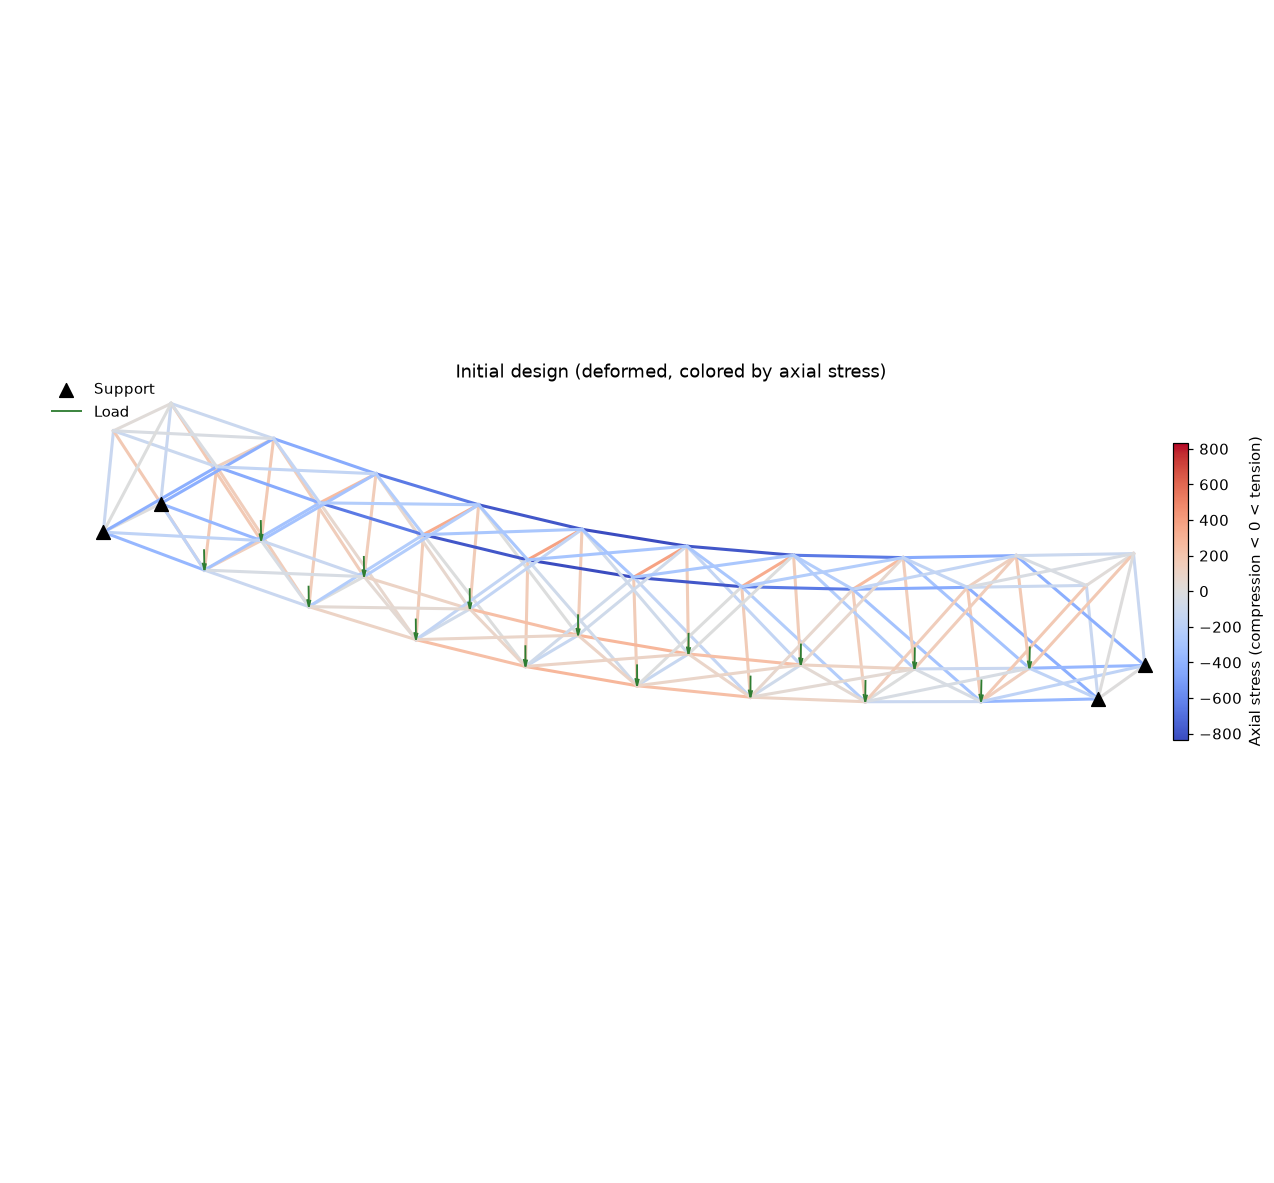

In [4]:
disp_scale = 0.3 / initial["max_displacement"]
stress_lim = initial["max_stress"]

ax = bridge.plot(u=initial["u"], sigma=initial["sigma"], scale=disp_scale,
                 sigma_limit=stress_lim, title="Initial design (deformed, colored by axial stress)")
plt.savefig("images/initial.png")
plt.show()

## 3. Optimization problem

The design variables $\mathbf{x}$ are the $x$- (along the span) and $z$- (height) coordinates
of all interior nodes. The problem reads

$$
\begin{aligned}
\min_{\mathbf{x}} \quad & C(\mathbf{x}) = \mathbf{f}^\top \mathbf{u}(\mathbf{x}) \\
\text{s.t.} \quad & V(\mathbf{x}) = \sum_i A_i\, l_i(\mathbf{x}) \le V_0 \\
& \mathbf{x}_0 - \Delta \le \mathbf{x} \le \mathbf{x}_0 + \Delta
\end{aligned}
$$

The box limits $\Delta$ keep the top and bottom chords from crossing each other.

Both $C$ and $V$ are written in PyTorch, so their gradients
$\partial C / \partial \mathbf{x}$ and $\partial V / \partial \mathbf{x}$ come from
**automatic differentiation** through the FE solve.

**MMA** replaces both functions in every iteration by convex, separable approximations

$$
\tilde{f}(\mathbf{x}) = r + \sum_i \frac{p_i}{U_i - x_i} + \frac{q_i}{x_i - L_i},
$$

with moving asymptotes $L_i, U_i$ that shrink when a variable oscillates and expand when it
moves steadily. The subproblem is solved exactly: $\mathbf{x}^*(\mu)$ follows in closed form, and
the Lagrange multiplier $\mu$ is found by bisection on the dual problem.

In [5]:
mask = torch.zeros_like(nodes, dtype=torch.bool)
interior = list(range(2, 18)) + list(range(22, 38))
mask[interior, 0] = True
mask[interior, 2] = True

limits = torch.zeros_like(nodes)
limits[:, 0] = 0.25
limits[:, 2] = 0.20  # chords are 0.5 apart, so they never meet

x_0 = nodes[mask]
x_min = x_0 - limits[mask]
x_max = x_0 + limits[mask]
V0 = bridge.volume().detach()


def set_design(x):
    bridge.nodes = bridge.nodes.detach().clone()
    bridge.nodes[mask] = x


def compliance(x):
    set_design(x)
    u, f = bridge.solve()
    return torch.inner(f.ravel(), u.ravel())


def volume_constraint(x):
    set_design(x)
    return bridge.volume() - V0


print(f"{len(x_0)} design variables")

64 design variables


In [6]:
history = optimize_mma(compliance, volume_constraint, x_0, x_min, x_max, n_iter=200, move=0.1)
set_design(history["x"][-1])
optimized = analyze(bridge)
print(f"Iterations: {len(history['x']) - 1}")
print(f"Compliance: {history['objective'][0]:.3f} -> {history['objective'][-1]:.3f}")

Iterations: 200
Compliance: 6.729 -> 2.370


## 4. Results

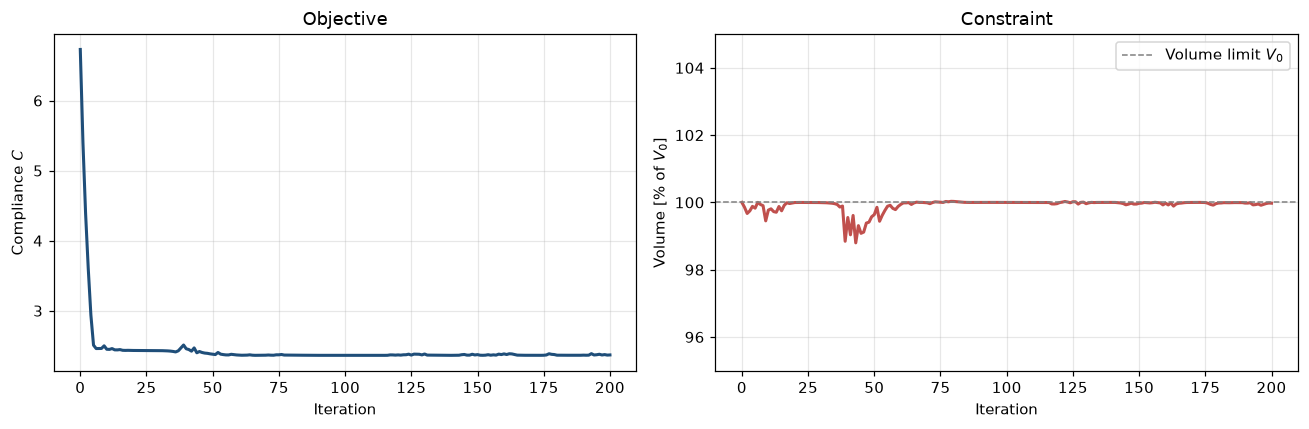

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history["objective"], color="#1f4e79", linewidth=2)
ax1.set_xlabel("Iteration")
ax1.set_ylabel("Compliance $C$")
ax1.set_title("Objective")
ax1.grid(alpha=0.3)

ax2.plot(100 * (torch.tensor(history["constraint"]) / V0 + 1), color="#c0504d", linewidth=2)
ax2.axhline(100, color="gray", linestyle="--", linewidth=1, label="Volume limit $V_0$")
ax2.set_xlabel("Iteration")
ax2.set_ylabel("Volume [% of $V_0$]")
ax2.set_title("Constraint")
ax2.set_ylim(95, 105)
ax2.legend()
ax2.grid(alpha=0.3)
fig.tight_layout()
plt.savefig("images/convergence.png", bbox_inches="tight")
plt.show()

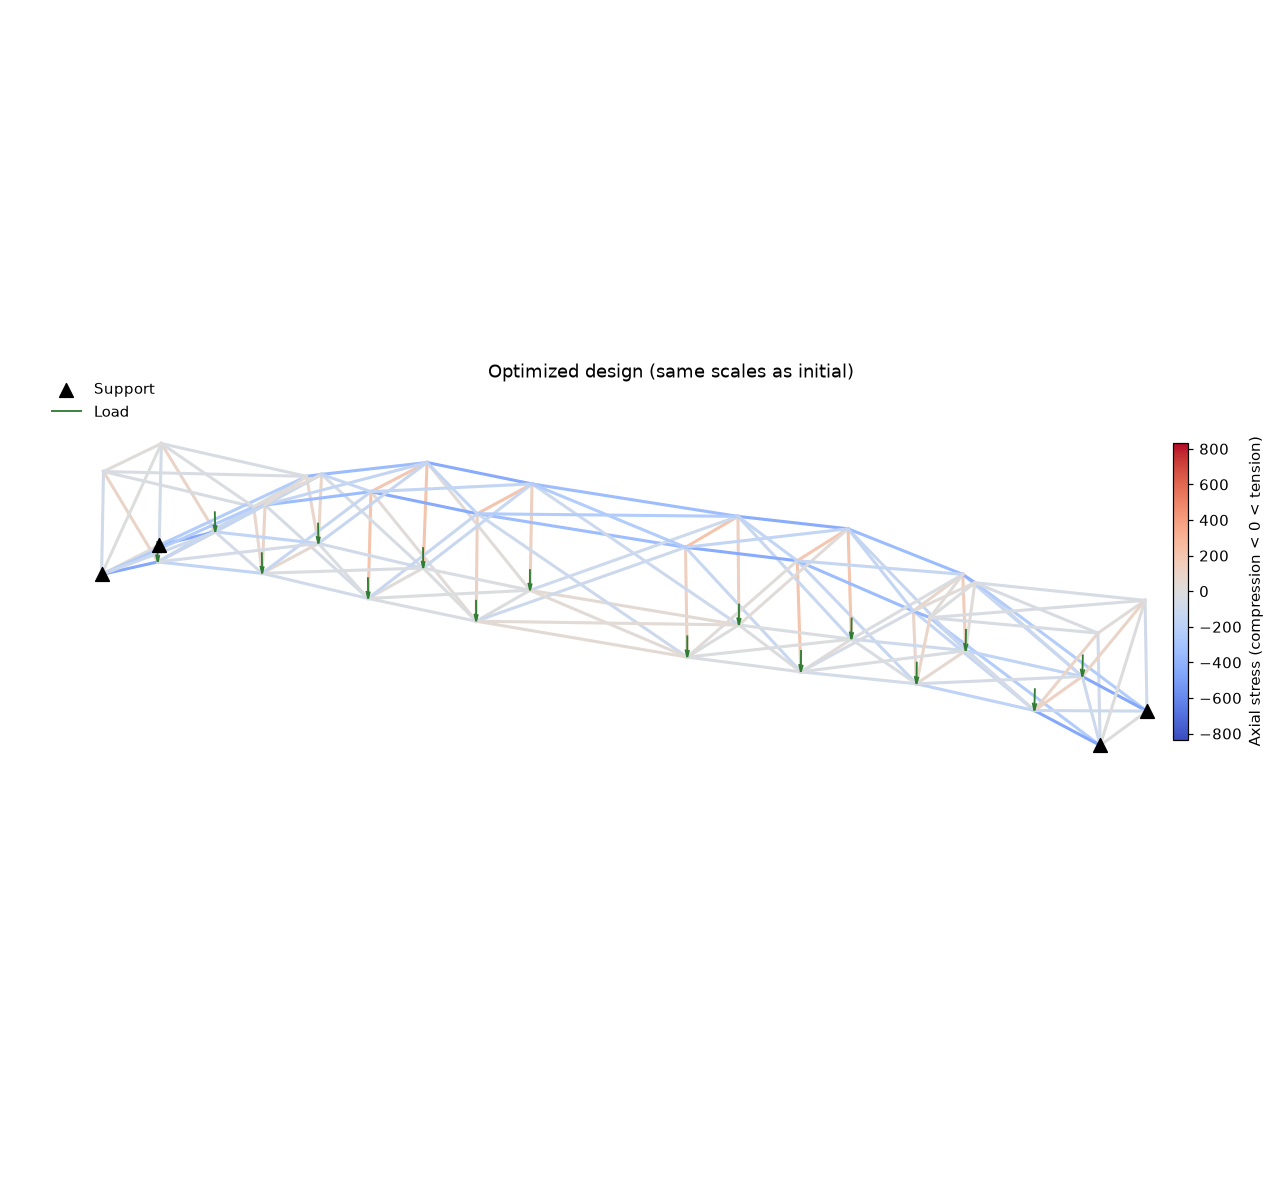

In [8]:
ax = bridge.plot(u=optimized["u"], sigma=optimized["sigma"], scale=disp_scale,
                 sigma_limit=stress_lim, title="Optimized design (same scales as initial)")
plt.savefig("images/optimized.png")
plt.show()

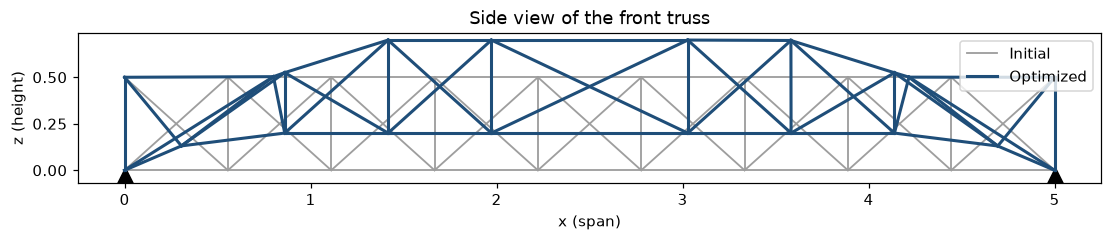

In [9]:
fig, ax = plt.subplots(figsize=(12, 3.2))
front = elements[(elements < 20).all(dim=1)]
for geom, color, label in [(initial_nodes, "#9e9e9e", "Initial"),
                           (bridge.nodes.detach(), "#1f4e79", "Optimized")]:
    for n, (a, b) in enumerate(front.tolist()):
        ax.plot(geom[[a, b], 0], geom[[a, b], 2], color=color, linewidth=2 if label == "Optimized" else 1.2,
                label=label if n == 0 else None)
ax.scatter(initial_nodes[[0, 18], 0], initial_nodes[[0, 18], 2] - 0.03, marker="^", s=120, color="black")
ax.set_aspect("equal")
ax.set_xlabel("x (span)")
ax.set_ylabel("z (height)")
ax.set_title("Side view of the front truss")
ax.legend(loc="upper right")
plt.savefig("images/side_view.png", bbox_inches="tight")
plt.show()

In [10]:
rows = [("Compliance", "compliance"), ("Max. displacement", "max_displacement"),
        ("Max. |axial stress|", "max_stress"), ("Material volume", "volume")]
print(f"{'':22}{'Initial':>12}{'Optimized':>12}{'Change':>10}")
for name, key in rows:
    a, b = initial[key], optimized[key]
    print(f"{name:22}{a:12.4f}{b:12.4f}{100 * (b / a - 1):+9.1f}%")

                           Initial   Optimized    Change
Compliance                  6.7294      2.3697    -64.8%
Max. displacement           5.9078      2.3328    -60.5%
Max. |axial stress|       834.3850    455.4582    -45.4%
Material volume             0.0952      0.0952     -0.0%


## 5. Conclusions

* With **the same amount of material**, moving the nodes reduces the compliance by about
  65 %, so the bridge becomes roughly three times stiffer. The peak bar stress also drops by
  about 45 %.
* The optimizer lifts the whole interior of the truss above the level of the supports. The end
  panels turn into steep inclined struts, so the deck load travels to the supports along a
  more direct, arch-like path instead of through bending of a flat girder.
* Both chords end up at the upper height limit. A larger allowed design space would therefore
  improve the design further. The box limits are an active design restriction, not just a
  numerical safeguard.
* PyTorch autograd provides exact sensitivities through the FE solve, so changing the objective
  (for example to stress or displacement) only needs a new Python function, not a new derivation.

*Note: the model is non-dimensional (unit-consistent but without physical units), so the
relative changes are the meaningful result.*

**Possible extensions:** stress and buckling constraints, simultaneous sizing of the cross
sections, symmetry enforcement, several load cases.